# Exploration de la source OpenSky Network

## 1. Contexte et objectif du notebook

Je commence l'exploration des données par OpenSky Network (`https://opensky-network.org/api/states/all`), la première des trois sources du projet.

L'idée est simple : avant de développer les modules d'ingestion pour OpenWeather et NewsAPI, je veux comprendre ce que me donne vraiment cette première source.

OpenSky fournit la variable cible potentielle (le retard, calculé à partir d'un écart horaire) et plusieurs features opérationnelles (position, altitude, vitesse, avion). Autant savoir dès maintenant à quoi ressemble cette donnée — complétude, fraîcheur, valeurs aberrantes — avant de construire le schéma en étoile en Phase 2.

Un point important : l'API `/states/all` renvoie un instantané de la position de tous les avions suivis au moment de la requête, pas un historique. Si je relance ce notebook demain, les chiffres seront différents. Les résultats commentés ci-dessous correspondent à une capture précise, dont l'horodatage est affiché juste après.


In [ ]:
import glob
import json
import os
import sys
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd

# On se place à la racine du projet pour retrouver src/, config/ et le fichier .env
RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.ingestion.opensky_client import OpenSkyClient

pd.set_option("display.max_columns", None)


C:\Users\jeann\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 2. Récupération et chargement des données

J'interroge l'API sur une bounding box couvrant l'Europe au sens large (latitude 34° à 71°, longitude -25° à 45°), plutôt qu'une zone limitée à la France. Avec une bbox restreinte à la France, je n'aurais récupéré qu'une poignée d'avions à un instant donné — pas assez pour une exploration statistique sérieuse (distributions, complétude, valeurs aberrantes). L'Europe entière donne un trafic dense et varié, plus proche de ce que verra le pipeline en production.

La cellule ci-dessous appelle l'API OpenSky en direct via `OpenSkyClient`, puis sauvegarde le résultat dans `data/raw/` (fichier JSON horodaté, non versionné). Si l'appel réseau échoue, elle retombe automatiquement sur le fichier le plus récent déjà présent dans `data/raw/`, pour que le reste du notebook reste exécutable même sans connexion.


In [ ]:
# Bounding box couvrant l'Europe au sens large : (lamin, lomin, lamax, lomax)
BBOX_EUROPE = (34.0, -25.0, 71.0, 45.0)
DOSSIER_DONNEES_BRUTES = os.path.join(RACINE_PROJET, "data", "raw")

try:
    client = OpenSkyClient()
    donnees_brutes = client.recuperer_vols_en_temps_reel(bbox=BBOX_EUROPE)
    chemin_fichier = client.sauvegarder_donnees_brutes(
        donnees_brutes, dossier=DOSSIER_DONNEES_BRUTES
    )
    print(f"Nouvel appel API réussi, données sauvegardées dans : {chemin_fichier}")
except Exception as erreur:
    print(f"Appel API impossible ({erreur}), réutilisation du dernier fichier disponible dans data/raw/.")
    fichiers_existants = sorted(glob.glob(os.path.join(DOSSIER_DONNEES_BRUTES, "opensky_*.json")))
    if not fichiers_existants:
        raise
    chemin_fichier = fichiers_existants[-1]
    with open(chemin_fichier, encoding="utf-8") as fichier:
        donnees_brutes = json.load(fichier)

# "time" est un timestamp Unix : l'instant de l'instantané côté OpenSky, pas
# l'instant de réception côté client.
horodatage_capture = datetime.fromtimestamp(donnees_brutes["time"], tz=timezone.utc)
print(f"Fichier utilisé : {chemin_fichier}")
print(f"Horodatage de la capture (UTC) : {horodatage_capture}")
print(f"Taille du fichier : {os.path.getsize(chemin_fichier) / 1024:.1f} Ko")


2026-08-15 10:06:43,796 - src.ingestion.opensky_client - INFO - Appel à l'API OpenSky Network réussi (code 200).
2026-08-15 10:06:43,916 - src.ingestion.opensky_client - INFO - Données brutes sauvegardées dans 'C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\raw\opensky_20260815_100643.json'.


Nouvel appel API réussi, données sauvegardées dans : C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\raw\opensky_20260815_100643.json
Fichier utilisé : C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\raw\opensky_20260815_100643.json
Horodatage de la capture (UTC) : 2026-08-15 08:06:36+00:00
Taille du fichier : 1110.2 Ko


In [3]:
# L'API renvoie les états sous forme de listes positionnelles, dans l'ordre
# documenté par la spécification officielle de l'endpoint /states/all.
NOMS_COLONNES_ETATS = [
    "icao24",
    "callsign",
    "origin_country",
    "time_position",
    "last_contact",
    "longitude",
    "latitude",
    "baro_altitude",
    "on_ground",
    "velocity",
    "true_track",
    "vertical_rate",
    "sensors",
    "geo_altitude",
    "squawk",
    "spi",
    "position_source",
]

df_vols = pd.DataFrame(donnees_brutes["states"], columns=NOMS_COLONNES_ETATS)

print(f"Nombre de lignes (avions observés) : {df_vols.shape[0]}")
print(f"Nombre de colonnes : {df_vols.shape[1]}")
df_vols.info()


Nombre de lignes (avions observés) : 4103
Nombre de colonnes : 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4103 entries, 0 to 4102
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   icao24           4103 non-null   object 
 1   callsign         4103 non-null   object 
 2   origin_country   4103 non-null   object 
 3   time_position    4103 non-null   int64  
 4   last_contact     4103 non-null   int64  
 5   longitude        4103 non-null   float64
 6   latitude         4103 non-null   float64
 7   baro_altitude    3742 non-null   float64
 8   on_ground        4103 non-null   bool   
 9   velocity         4103 non-null   float64
 10  true_track       4103 non-null   float64
 11  vertical_rate    3725 non-null   float64
 12  sensors          0 non-null      object 
 13  geo_altitude     3656 non-null   float64
 14  squawk           3417 non-null   object 
 15  spi              4103 non-null   bool   

## 3. Combien de vols récupère-t-on en un seul appel ? Quelle est la fraîcheur des données ?

Le champ `time_position` indique quand la position d'un avion a été mesurée par les récepteurs ADS-B — un instant qui peut être légèrement antérieur à celui de la requête (`time`, au niveau global de la réponse). Je calcule l'écart entre les deux pour voir à quel point les positions reçues sont vraiment fraîches.


In [4]:
df_vols["age_position_secondes"] = donnees_brutes["time"] - df_vols["time_position"]

print(f"Nombre d'avions récupérés en un seul appel : {len(df_vols)}")
print()
print("Distribution de l'âge des positions (en secondes) :")
print(df_vols["age_position_secondes"].describe())
print()
seuil_secondes = 300
nb_positions_anciennes = (df_vols["age_position_secondes"] > seuil_secondes).sum()
part_positions_anciennes = nb_positions_anciennes / len(df_vols) * 100
print(
    f"Positions vieilles de plus de {seuil_secondes} s (5 min) : "
    f"{nb_positions_anciennes} ({part_positions_anciennes:.1f} % du total)"
)


Nombre d'avions récupérés en un seul appel : 4103

Distribution de l'âge des positions (en secondes) :
count    4103.000000
mean       30.710699
std       226.412828
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max      9431.000000
Name: age_position_secondes, dtype: float64

Positions vieilles de plus de 300 s (5 min) : 66 (1.6 % du total)


**Ce que ça donne** : un seul appel a renvoyé 4 103 avions sur la zone européenne choisie. La moitié des positions ont moins d'une seconde d'écart (quasiment du temps réel), mais la moyenne (environ 31 s) est beaucoup plus haute que la médiane, tirée vers le haut par une minorité de positions bien plus anciennes (jusqu'à 9 400 s, soit plus de 2h30). Ce sont probablement des avions sortis de la couverture des récepteurs ADS-B alors qu'ils étaient encore suivis — l'API continue d'afficher leur dernière position connue. Environ 1,6 % des positions (66 sur 4 103) dépassent les 5 minutes : une proportion faible, mais qu'il faudra filtrer explicitement en Phase 2, une position vieille de plusieurs heures ne devant pas être traitée comme une observation temps réel.


## 4. Quels champs sont systématiquement vides ou nuls, et dans quelle proportion ?

Je calcule le taux de complétude de chaque colonne (proportion de valeurs non nulles), puis je l'affiche pour repérer tout de suite les colonnes qui posent problème.


sensors                    0.00
squawk                    83.28
geo_altitude              89.11
vertical_rate             90.79
baro_altitude             91.20
icao24                   100.00
spi                      100.00
true_track               100.00
velocity                 100.00
on_ground                100.00
latitude                 100.00
longitude                100.00
last_contact             100.00
time_position            100.00
origin_country           100.00
callsign                 100.00
position_source          100.00
age_position_secondes    100.00
dtype: float64


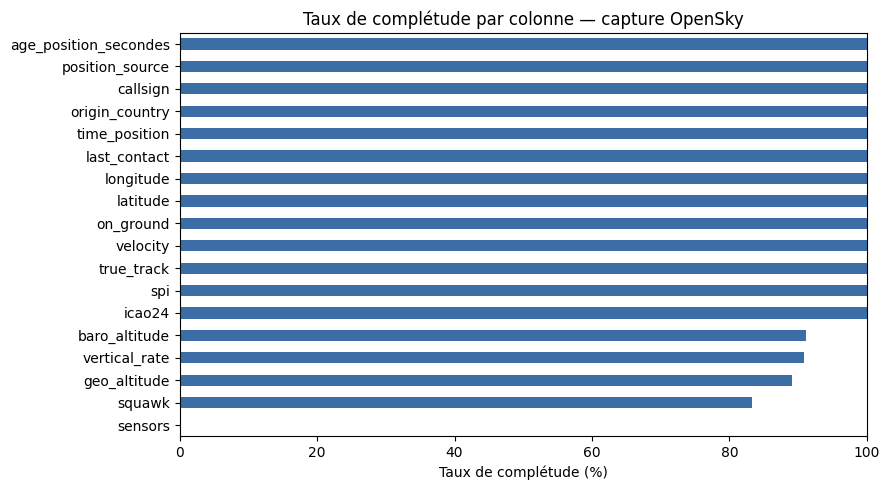

In [5]:
taux_completude = (df_vols.notna().mean() * 100).sort_values()
print(taux_completude.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
taux_completude.plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Taux de complétude (%)")
ax.set_title("Taux de complétude par colonne — capture OpenSky")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


In [6]:
# Est-ce que les baro_altitude manquants sont surtout des avions au sol ?
taux_manquant_baro_par_statut = df_vols.groupby("on_ground")["baro_altitude"].apply(
    lambda colonne: colonne.isna().mean() * 100
)
print("Taux de baro_altitude manquant selon le statut au sol (on_ground) :")
print(taux_manquant_baro_par_statut.round(2))


Taux de baro_altitude manquant selon le statut au sol (on_ground) :
on_ground
False     0.05
True     95.48
Name: baro_altitude, dtype: float64


**Ce que ça donne** : la colonne `sensors` est vide à 100 % — ce champ n'est documenté par OpenSky que pour des requêtes authentifiées avec filtrage par capteur, ce qui n'est pas notre cas (requête par bounding box) ; elle est inexploitable et pourra disparaître dès le nettoyage. `squawk` (code transpondeur) manque pour environ 17 % des avions, `geo_altitude` pour environ 11 %, `baro_altitude` et `vertical_rate` pour environ 9 % chacun. En croisant avec `on_ground`, l'hypothèse se confirme : quand l'avion est au sol, `baro_altitude` manque dans plus de 95 % des cas (logique, l'altitude en vol n'a pas de sens au sol), contre moins de 0,1 % pour les avions en vol. Ce n'est donc pas un problème de qualité de la source, mais un comportement attendu du protocole ADS-B — à gérer via une logique conditionnelle (distinguer sol/vol) plutôt qu'une imputation générique.


## 5. Quelle est la distribution géographique des positions récupérées ?

Je visualise les positions sous forme de nuage de points latitude/longitude — un simple scatter plot suffit à voir la répartition géographique, pas besoin d'ajouter une librairie de cartographie pour ça.


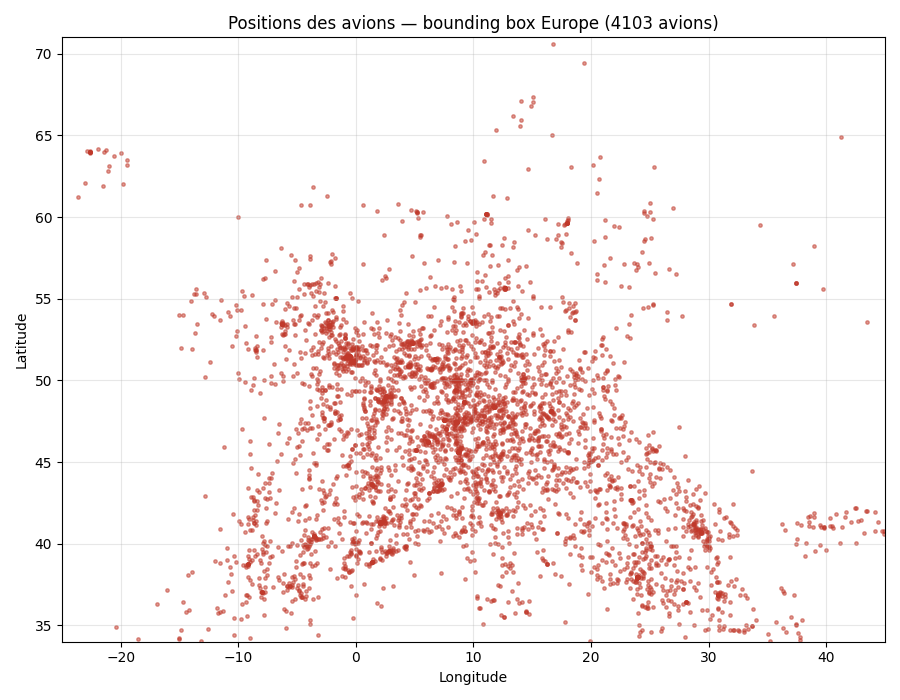

Nombre de pays d'origine distincts (origin_country) : 77

Top 10 des pays d'origine les plus représentés :
origin_country
United Kingdom    494
Germany           441
Ireland           334
Turkey            301
Malta             267
France            222
Spain             190
United States     184
Austria           159
Poland            135
Name: count, dtype: int64


In [7]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df_vols["longitude"], df_vols["latitude"], s=6, alpha=0.5, color="#c0392b")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Positions des avions — bounding box Europe ({len(df_vols)} avions)")
ax.set_xlim(BBOX_EUROPE[1], BBOX_EUROPE[3])
ax.set_ylim(BBOX_EUROPE[0], BBOX_EUROPE[2])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

nb_pays_distincts = df_vols["origin_country"].nunique()
print(f"Nombre de pays d'origine distincts (origin_country) : {nb_pays_distincts}")
print()
print("Top 10 des pays d'origine les plus représentés :")
print(df_vols["origin_country"].value_counts().head(10))


**Ce que ça donne** : le nuage de points dessine bien les grands couloirs aériens européens (axe Londres-Paris-Francfort, arc méditerranéen), avec une densité plus forte au centre et à l'ouest de l'Europe qu'aux marges de la bounding box. La colonne `origin_country` recense 77 pays d'origine distincts, dominés par le Royaume-Uni, l'Allemagne, l'Irlande, la Turquie et Malte (souvent lié à l'immatriculation de la compagnie plutôt qu'au pays réellement survolé). Cette diversité confirme que la bbox européenne capture un trafic international varié — plus représentatif pour la suite du projet qu'un trafic purement domestique limité à la France.


## 6. Quels types de données par colonne, et présence de valeurs aberrantes ?

Je vérifie les types Python réels des colonnes numériques, puis je cherche des valeurs qui sortent des bornes physiquement plausibles : altitude négative, vitesse extrême, coordonnées hors de [-90, 90] pour la latitude et [-180, 180] pour la longitude.


In [8]:
print("Types de données par colonne :")
print(df_vols.dtypes)
print()

nb_altitude_baro_negative = (df_vols["baro_altitude"] < 0).sum()
nb_altitude_geo_negative = (df_vols["geo_altitude"] < 0).sum()
nb_latitude_hors_bornes = ((df_vols["latitude"] < -90) | (df_vols["latitude"] > 90)).sum()
nb_longitude_hors_bornes = ((df_vols["longitude"] < -180) | (df_vols["longitude"] > 180)).sum()

print(f"Altitude barométrique négative : {nb_altitude_baro_negative} ligne(s)")
print(f"Altitude géométrique négative : {nb_altitude_geo_negative} ligne(s)")
print(f"Latitude hors bornes [-90, 90] : {nb_latitude_hors_bornes} ligne(s)")
print(f"Longitude hors bornes [-180, 180] : {nb_longitude_hors_bornes} ligne(s)")
print()
print("Statistiques descriptives des colonnes numériques clés :")
print(df_vols[["baro_altitude", "geo_altitude", "velocity", "vertical_rate"]].describe())
print()

ligne_vitesse_max = df_vols.loc[df_vols["velocity"].idxmax()]
print("Ligne présentant la vitesse la plus élevée (valeur suspecte à examiner) :")
print(
    ligne_vitesse_max[
        ["icao24", "callsign", "velocity", "age_position_secondes", "on_ground"]
    ]
)


Types de données par colonne :
icao24                    object
callsign                  object
origin_country            object
time_position              int64
last_contact               int64
longitude                float64
latitude                 float64
baro_altitude            float64
on_ground                   bool
velocity                 float64
true_track               float64
vertical_rate            float64
sensors                   object
geo_altitude             float64
squawk                    object
spi                         bool
position_source            int64
age_position_secondes      int64
dtype: object

Altitude barométrique négative : 6 ligne(s)
Altitude géométrique négative : 1 ligne(s)
Latitude hors bornes [-90, 90] : 0 ligne(s)
Longitude hors bornes [-180, 180] : 0 ligne(s)

Statistiques descriptives des colonnes numériques clés :
       baro_altitude  geo_altitude     velocity  vertical_rate
count    3742.000000   3656.000000  4103.000000    3725.00000

**Ce que ça donne** : les types Python sont cohérents avec ce qu'on attend (numériques en `float64`/`int64`, `on_ground`/`spi` en `bool`, identifiants et texte en `object`). Six altitudes barométriques légèrement négatives ont été repérées (de -7,6 à -30,5 mètres), sur des avions à la fois au sol et en vol : probablement un écart de calibration du capteur par rapport à la pression de référence au niveau de la mer (l'avion est alors juste après le décollage ou juste avant l'atterrissage) plutôt qu'une vraie erreur de mesure — ces valeurs seront à plafonner à zéro plutôt qu'à supprimer en Phase 2. Plus notable : une vitesse de 1 298 m/s (environ 4 700 km/h), incompatible avec n'importe quel avion civil ou militaire courant. Cette valeur correspond à une position vieille de plus de 5 200 secondes (85 minutes), ce qui confirme l'hypothèse d'une donnée périmée liée à une position "fantôme" (avion sorti de couverture radar). D'où l'idée, en Phase 2, d'une règle de nettoyage qui combine un seuil de fraîcheur et un seuil physique de vitesse maximale, plutôt qu'un filtre sur la vitesse seule.


## 7. Quel volume de données cela représente-t-il ?

Je calcule la taille du fichier JSON de cette capture, puis je projette le volume total sur la durée du projet selon différentes fréquences de collecte.


In [9]:
taille_octets = os.path.getsize(chemin_fichier)
taille_ko = taille_octets / 1024
taille_mo = taille_ko / 1024

print(f"Nombre de lignes de cette capture : {len(df_vols)}")
print(f"Taille du fichier JSON brut : {taille_octets} octets ({taille_ko:.1f} Ko / {taille_mo:.3f} Mo)")
print()

# Volume total si on répète cette collecte pendant 14 jours
DUREE_PROJET_JOURS = 14
print(f"Projection sur {DUREE_PROJET_JOURS} jours de collecte, selon la fréquence choisie :")
for frequence_minutes in (5, 10, 15):
    nb_captures = DUREE_PROJET_JOURS * 24 * 60 / frequence_minutes
    volume_total_mo = nb_captures * taille_mo
    volume_total_go = volume_total_mo / 1024
    print(
        f"  - toutes les {frequence_minutes:>2} min -> {nb_captures:.0f} captures, "
        f"volume total estimé : {volume_total_mo:.0f} Mo (~{volume_total_go:.2f} Go)"
    )


Nombre de lignes de cette capture : 4103
Taille du fichier JSON brut : 1136846 octets (1110.2 Ko / 1.084 Mo)

Projection sur 14 jours de collecte, selon la fréquence choisie :
  - toutes les  5 min -> 4032 captures, volume total estimé : 4371 Mo (~4.27 Go)
  - toutes les 10 min -> 2016 captures, volume total estimé : 2186 Mo (~2.13 Go)
  - toutes les 15 min -> 1344 captures, volume total estimé : 1457 Mo (~1.42 Go)


**Ce que ça donne** : une capture représente environ 1 Mo de JSON brut pour près de 4 000 avions sur l'Europe. Sur 14 jours, une collecte toutes les 5 minutes représenterait environ 4 Go de données brutes, contre environ 1,4 Go pour une collecte toutes les 15 minutes. C'est un volume tout à fait gérable sur disque local ou dans PostgreSQL une fois structuré (Phase 2), mais ça montre bien qu'un stockage JSON brut non compressé sur toute la durée du projet finit par peser plusieurs giga-octets. Une fréquence de 10 à 15 minutes semble être un bon compromis entre fraîcheur et volumétrie : l'essentiel des vols commerciaux dure largement plus de 15 minutes, donc collecter toutes les 5 minutes n'apporterait pas grand-chose de plus.


## 8. Rapport de profiling automatisé (ydata-profiling)

L'exploration ci-dessus répond à des questions précises, choisies parce qu'elles débouchent sur des décisions concrètes pour le pipeline. Elle reste forcément partielle : elle ne couvre pas systématiquement toutes les colonnes ni toutes les corrélations possibles. Le rapport `ydata-profiling` généré ci-dessous complète cette exploration ciblée par une vue exhaustive, utile pour vérifier que rien d'important n'a été manqué.


In [10]:
from ydata_profiling import ProfileReport

DOSSIER_PROFILING = os.path.join(RACINE_PROJET, "data", "profiling_reports")
os.makedirs(DOSSIER_PROFILING, exist_ok=True)
chemin_rapport = os.path.join(DOSSIER_PROFILING, "opensky_profiling_report.html")

warnings.filterwarnings("ignore", category=FutureWarning, module="ydata_profiling")

rapport = ProfileReport(
    df_vols,
    title="Rapport de profiling - OpenSky Network",
    explorative=True,
    progress_bar=False,
)
rapport.to_file(chemin_rapport)

print(f"Rapport de profiling généré : {chemin_rapport}")


Rapport de profiling généré : C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\profiling_reports\opensky_profiling_report.html


## 9. Synthèse et conclusions

**Complétude générale** : sur cette capture, 5 des 17 champs ont des valeurs manquantes. `sensors` est vide à 100 % et n'apporte rien dans notre cas d'usage (requête par bounding box, sans authentification par capteur) — à supprimer dès le nettoyage. `squawk`, `geo_altitude`, `baro_altitude` et `vertical_rate` sont complets entre 83 % et 91 %, mais cette non-complétude est structurelle (liée au statut sol/vol de l'avion), pas aléatoire — à traiter par une logique conditionnelle plutôt qu'une imputation générique.

**Anomalies repérées** :
- Six altitudes barométriques très légèrement négatives (entre -7,6 et -30,5 mètres), à plafonner à zéro plutôt qu'à exclure.
- Une vitesse extrême (environ 1 298 m/s) associée à une position vieille de plus de 85 minutes — un filtre combinant fraîcheur et plausibilité physique sera nécessaire avant d'utiliser cette donnée comme feature.
- Aucune coordonnée hors des bornes géographiques valides.
- Environ 1,6 % des positions ont plus de 5 minutes d'ancienneté, identifiables via `age_position_secondes`, à recalculer de la même façon dans le pipeline de nettoyage (Phase 2).

**Pour la suite (Phase 2)** :
1. Supprimer la colonne `sensors` (aucune valeur informative).
2. Ajouter une règle de nettoyage sur `baro_altitude`/`geo_altitude` (plancher à zéro) et sur `velocity` combinée à l'âge de la position (rejet des valeurs implausibles sur des positions périmées).
3. Garder `on_ground` comme variable de segmentation avant de traiter les champs d'altitude, plutôt que de les traiter tous de la même façon.
4. Retenir une fréquence de collecte de 10 à 15 minutes pour équilibrer fraîcheur et volumétrie.
5. Nettoyer les espaces du champ `callsign` (`strip()`) avant toute jointure avec les autres sources — une partie des valeurs ne contient que des espaces une fois nettoyées.

Ces constats seront repris dans le chapitre "Data Profiling" du Rendu 1 (`docs/rendu1_decouverte_exploration.md`).
